In [1]:
# import dependencies
import os
import numpy as np
import pandas as pd
import cell2cell as c2c
import scanpy as sc
import loompy as lp
from MulticoreTSNE import MulticoreTSNE as TSNE
from multiprocessing import cpu_count
from ctxcore.genesig import GeneSignature

from sklearn.metrics import silhouette_samples, silhouette_score

import warnings
warnings.filterwarnings('ignore')

/oceanus/collab/InternalJeff/users/gxm300/anaconda3/envs/pyscenic_stable/lib/python3.7/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
cpu_cnt = cpu_count()
cpu_cnt

80

In [3]:
# set variables for file paths to read from and write to:

# set a working directory
wdir = "/oceanus/collab/APLIN_LAB/Data/Public/scRNAseq/Alvarez-Breckenridge_scRNAseq"
os.chdir( wdir )

# path to mtx file
f_mtx = "BM_c1000_raw.mtx"

# path to var gene names
f_genes = "BM_c1000_preQC_genes_raw.tsv"

# path to obs data
f_obs = "BM_c1000_base_metadata.tsv"

# path to umap info
f_post_umap = "postQC_c1000_spatial.tsv"

# path to unfiltered loom file (this will be created in the optional steps below)
f_loom_path_unfilt = "Alvarez-Breckenridge_scRNAseq_unfiltered.loom" # test dataset, n=500 cells

# # path to loom file with basic filtering applied (this will be created in the "initial filtering" step below). Optional.
f_loom_path_scenic = "Alvarez-Breckenridge_scRNAseq_filtered_scenic.loom"

# path to anndata object, which will be updated to store Scanpy results as they are generated below
f_anndata_path = "Alvarez-Breckenridge_scRNAseq_anndata.h5ad"

# path to pyscenic output
f_pyscenic_output = "Alvarez-Breckenridge_scRNAseq_pyscenic_output.loom"

# loom output, generated from a combination of Scanpy and pySCENIC results:
f_final_loom = 'Alvarez-Breckenridge_scRNAseq_scenic_integrated-output.loom'

In [4]:
sc.settings.verbosity = 3 # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_versions()
sc.set_figure_params(dpi=150, fontsize=10, dpi_save=600)

-----
anndata     0.8.0
scanpy      1.9.3
-----
MulticoreTSNE       NA
PIL                 9.4.0
attr                24.2.0
backcall            0.2.0
beta_ufunc          NA
binom_ufunc         NA
bottleneck          1.3.5
cairo               1.21.0
cell2cell           0.7.3
cffi                1.15.1
cloudpickle         2.2.1
colorama            0.4.6
ctxcore             0.2.0
cycler              0.10.0
cython_runtime      NA
cytoolz             0.12.3
dask                2022.02.0
dateutil            2.9.0
debugpy             1.6.3
decorator           5.1.1
defusedxml          0.7.1
entrypoints         0.4
frozendict          2.4.7
fsspec              2023.1.0
h5py                3.7.0
igraph              0.7.1
ipykernel           6.16.2
ipython_genutils    0.2.0
jedi                0.19.1
jinja2              3.1.4
joblib              1.3.2
kiwisolver          1.4.4
kneed               0.8.5
leidenalg           0.8.3
llvmlite            0.39.1
loompy              3.0.8
louvain        

In [5]:
# Set maximum number of jobs for Scanpy.
sc.settings.njobs = cpu_cnt

# Expression data import

## Reading in data from multiple files and merging into adata object 

In [6]:
# Load in mtx to serve as initial adata object
adata = sc.read_mtx(f_mtx)
adata = adata.transpose()

In [7]:
adata

AnnData object with n_obs × n_vars = 15373 × 33170

In [8]:
gene_names = pd.read_csv(f_genes, delimiter = "\t", header = None)
gene_names.columns = ["gene_names"]

In [9]:
gene_names

,gene_names
0,A1BG
1,A1BG-AS1
2,A1CF
3,A2M
4,A2M-AS1
...,...
33165,ZXDC
33166,ZYG11A
33167,ZYG11B
33168,ZYX


In [10]:
adata.var_names = gene_names["gene_names"]

In [11]:
adata.var

""
gene_names
A1BG
A1BG-AS1
A1CF
A2M
A2M-AS1
...
ZXDC
ZYG11A
ZYG11B


In [12]:
meta = pd.read_csv(f_obs, delimiter = "\t", skiprows = [1])
meta = meta.rename(columns={'NAME': 'Cell'})

In [13]:
meta

,Cell,biosample_id,donor_id,species,species__ontology_label,disease,disease__ontology_label,organ,organ__ontology_label,library_preparation_protocol,library_preparation_protocol__ontology_label,sex
0,M21_3p2_Lym_A01_S1,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
1,M21_3p2_Lym_A02_S2,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
2,M21_3p2_Lym_A03_S3,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
3,M21_3p2_Lym_A04_S4,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
4,M21_3p2_Lym_A05_S5,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
...,...,...,...,...,...,...,...,...,...,...,...,...
15368,M29p3_CD3_C12_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
15369,M29p3_CD3_D01_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
15370,M29p3_CD3_D02_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
15371,M29p3_CD3_D03_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown


In [14]:
adata.obs = meta.drop(["Cell"], axis=1)
adata.obs_names = meta["Cell"]
adata.obs

,biosample_id,donor_id,species,species__ontology_label,disease,disease__ontology_label,organ,organ__ontology_label,library_preparation_protocol,library_preparation_protocol__ontology_label,sex
Cell,,,,,,,,,,,
M21_3p2_Lym_A01_S1,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
M21_3p2_Lym_A02_S2,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
M21_3p2_Lym_A03_S3,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
M21_3p2_Lym_A04_S4,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
M21_3p2_Lym_A05_S5,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
...,...,...,...,...,...,...,...,...,...,...,...
M29p3_CD3_C12_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
M29p3_CD3_D01_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown
M29p3_CD3_D02_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown


# Initial/basic filtering

In [15]:
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from mpl_toolkits.mplot3d import Axes3D

In [16]:
nCountsPerGene = np.sum(adata.X, axis=0)
nCellsPerGene = np.sum(adata.X>0, axis=0)

# Show info
print("Number of counts (in the dataset units) per gene:", nCountsPerGene.min(), " - " ,nCountsPerGene.max())
print("Number of cells in which each gene is detected:", nCellsPerGene.min(), " - " ,nCellsPerGene.max())

Number of counts (in the dataset units) per gene: 0.0  -  277865180.0
Number of cells in which each gene is detected: 0  -  15371


In [17]:
nCells=adata.X.shape[0]

# pySCENIC thresholds
minCountsPerGene=3*.01*nCells # 3 counts in 1% of cells
print("minCountsPerGene: ", minCountsPerGene)

minSamples=.01*nCells # 1% of cells
print("minSamples: ", minSamples)

minCountsPerGene:  461.19
minSamples:  153.73


In [18]:
# simply compute the number of genes per cell (computers 'n_genes' column)
sc.pp.filter_cells(adata, min_genes=0)
# mito and genes/counts cuts
mito_genes = adata.var_names.str.startswith('MT-')
# for each cell compute fraction of counts in mito genes vs. all genes
adata.obs['percent_mito'] = np.sum(
    adata[:, mito_genes].X, axis=1).A1 / np.sum(adata.X, axis=1).A1
# add the total counts per cell as observations-annotation to adata
adata.obs['n_counts'] = adata.X.sum(axis=1).A1

# Diagnostic Plots, pre-filtering

### Number of genes expressed per cell

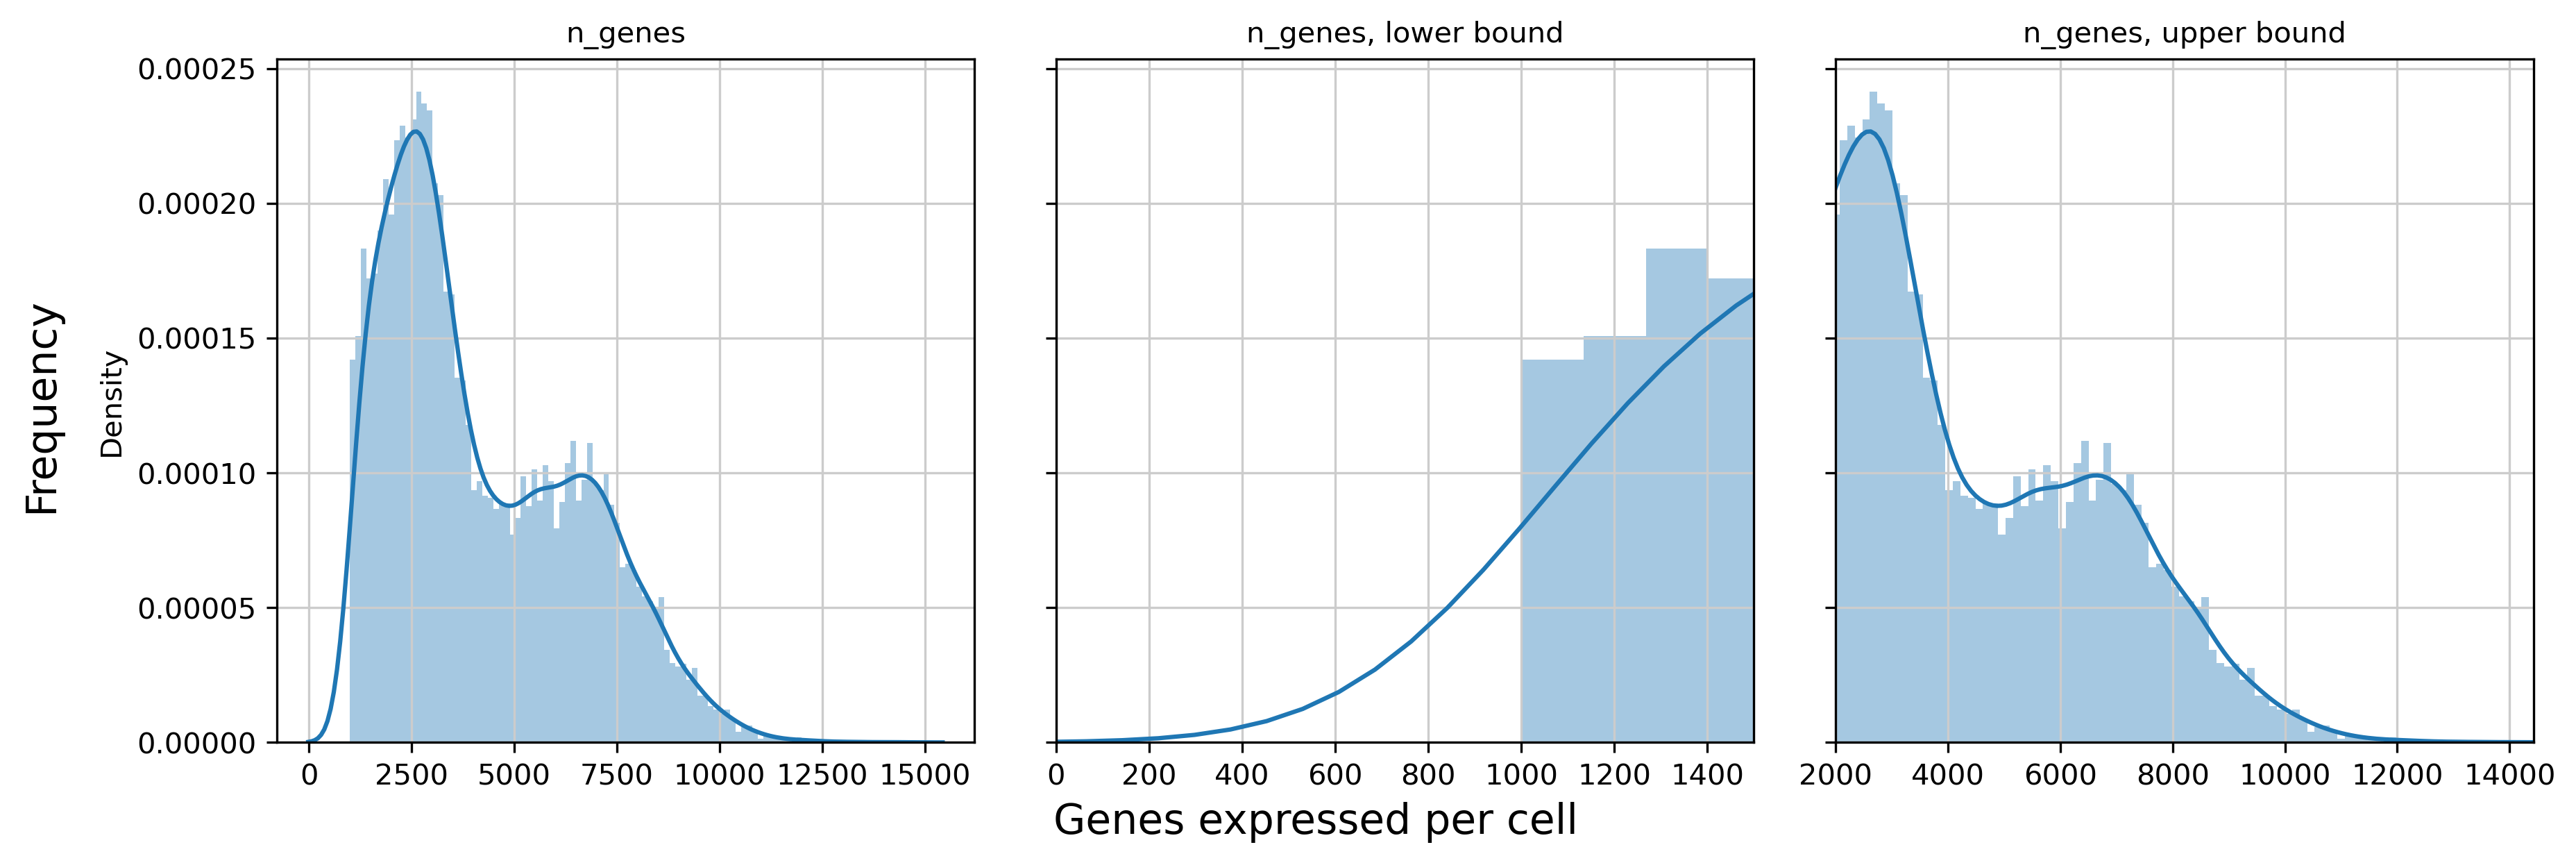

In [19]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=True)

x = adata.obs['n_genes']
x_lowerbound = 1500
x_upperbound = 2000
nbins=100

sns.distplot(x, ax=ax1, norm_hist=True, bins=nbins)
sns.distplot(x, ax=ax2, norm_hist=True, bins=nbins)
sns.distplot(x, ax=ax3, norm_hist=True, bins=nbins)

ax2.set_xlim(0,x_lowerbound)
ax3.set_xlim(x_upperbound, adata.obs['n_genes'].max() )

for ax in (ax1,ax2,ax3): 
  ax.set_xlabel('')

ax1.title.set_text('n_genes')
ax2.title.set_text('n_genes, lower bound')
ax3.title.set_text('n_genes, upper bound')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')
fig.text(0.5, 0.0, 'Genes expressed per cell', ha='center', va='center', size='x-large')

fig.tight_layout()

### Percentage of mitochondrial reads per cell

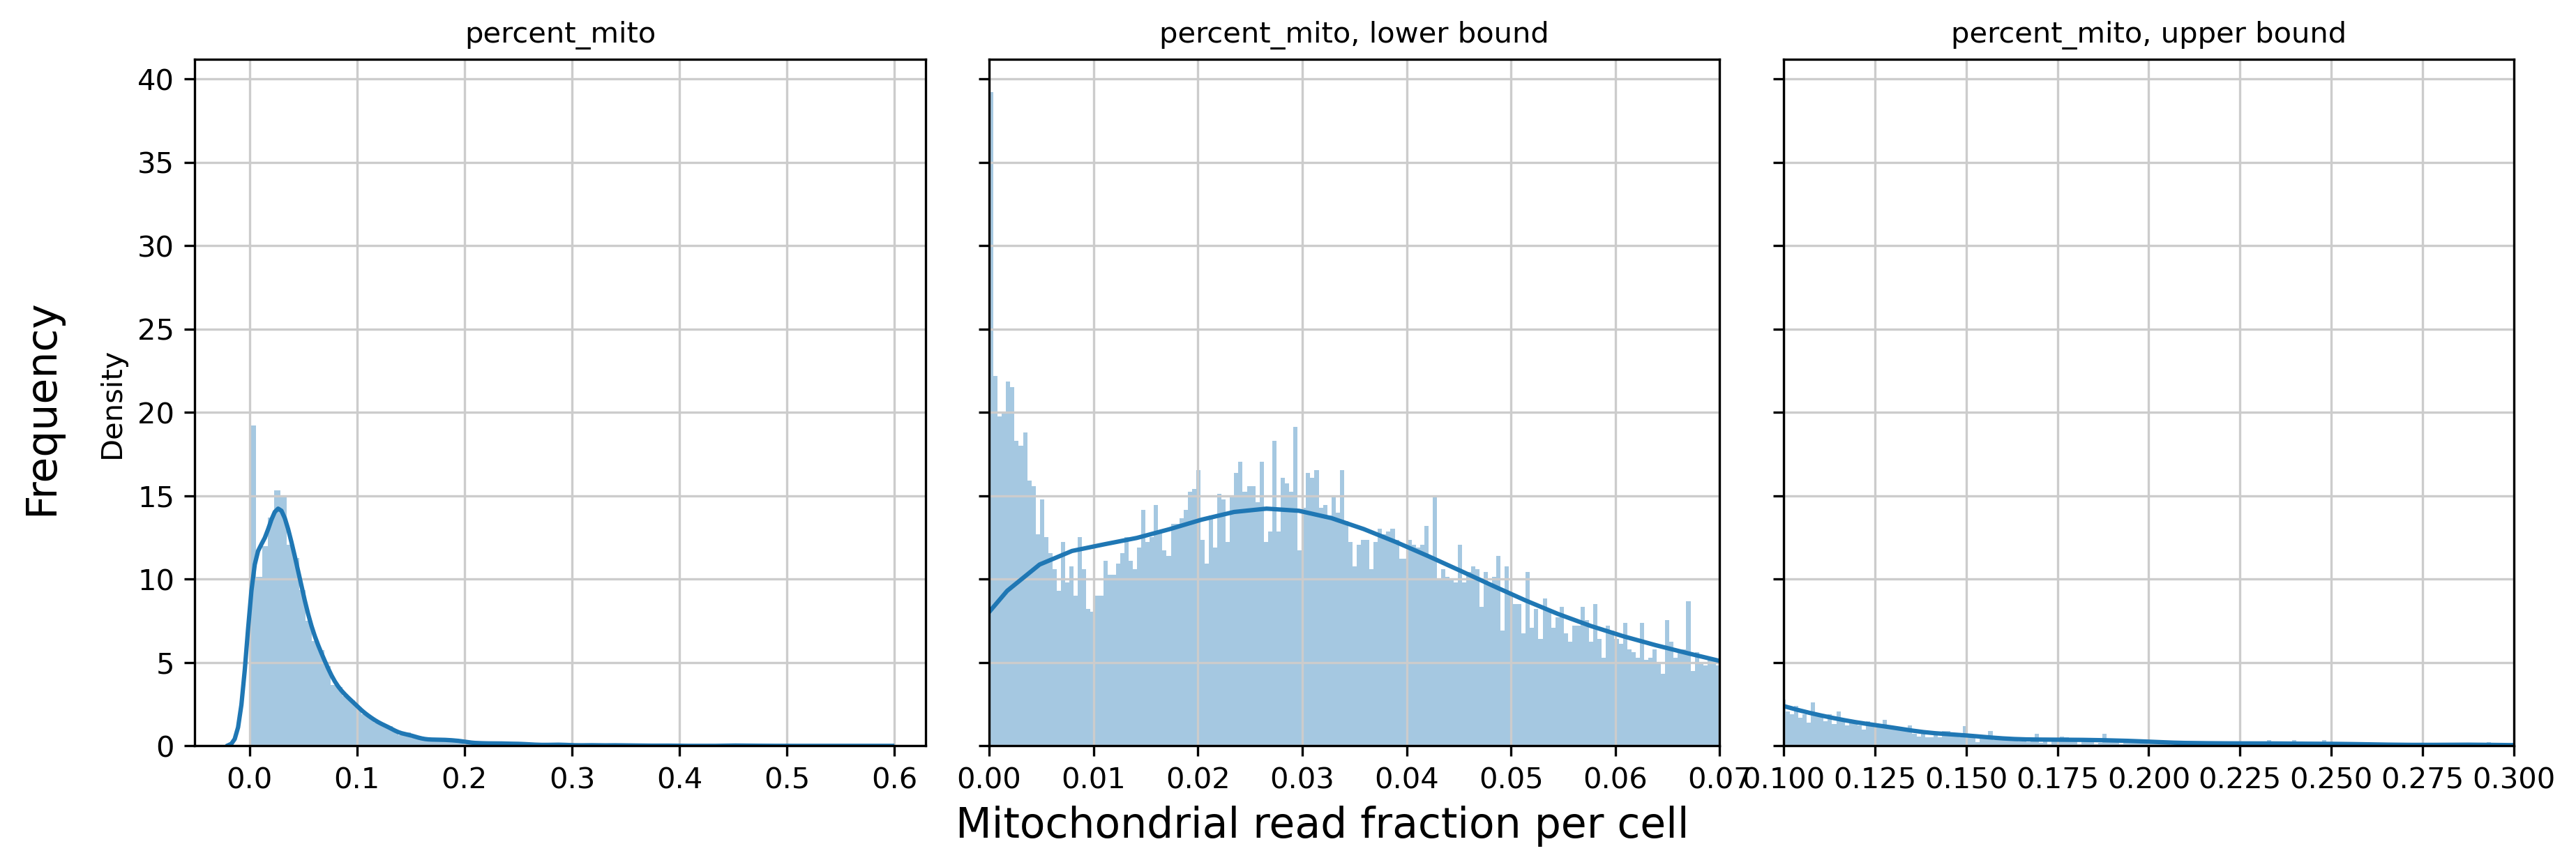

In [20]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=True)

x = adata.obs['percent_mito']
x_lowerbound = [0.0, 0.07 ]
x_upperbound = [ 0.10, 0.3 ]
nbins=100

sns.distplot(x, ax=ax1, norm_hist=True, bins=nbins)
sns.distplot(x, ax=ax2, norm_hist=True, bins=int(nbins/(x_lowerbound[1]-x_lowerbound[0])) )
sns.distplot(x, ax=ax3, norm_hist=True, bins=int(nbins/(x_upperbound[1]-x_upperbound[0])) )

ax2.set_xlim(x_lowerbound[0], x_lowerbound[1])
ax3.set_xlim(x_upperbound[0], x_upperbound[1] )
for ax in (ax1,ax2,ax3): 
  ax.set_xlabel('')

ax1.title.set_text('percent_mito')
ax2.title.set_text('percent_mito, lower bound')
ax3.title.set_text('percent_mito, upper bound')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')
fig.text(0.5, 0.0, 'Mitochondrial read fraction per cell', ha='center', va='center', size='x-large')

fig.tight_layout()

### Three panel plot summary

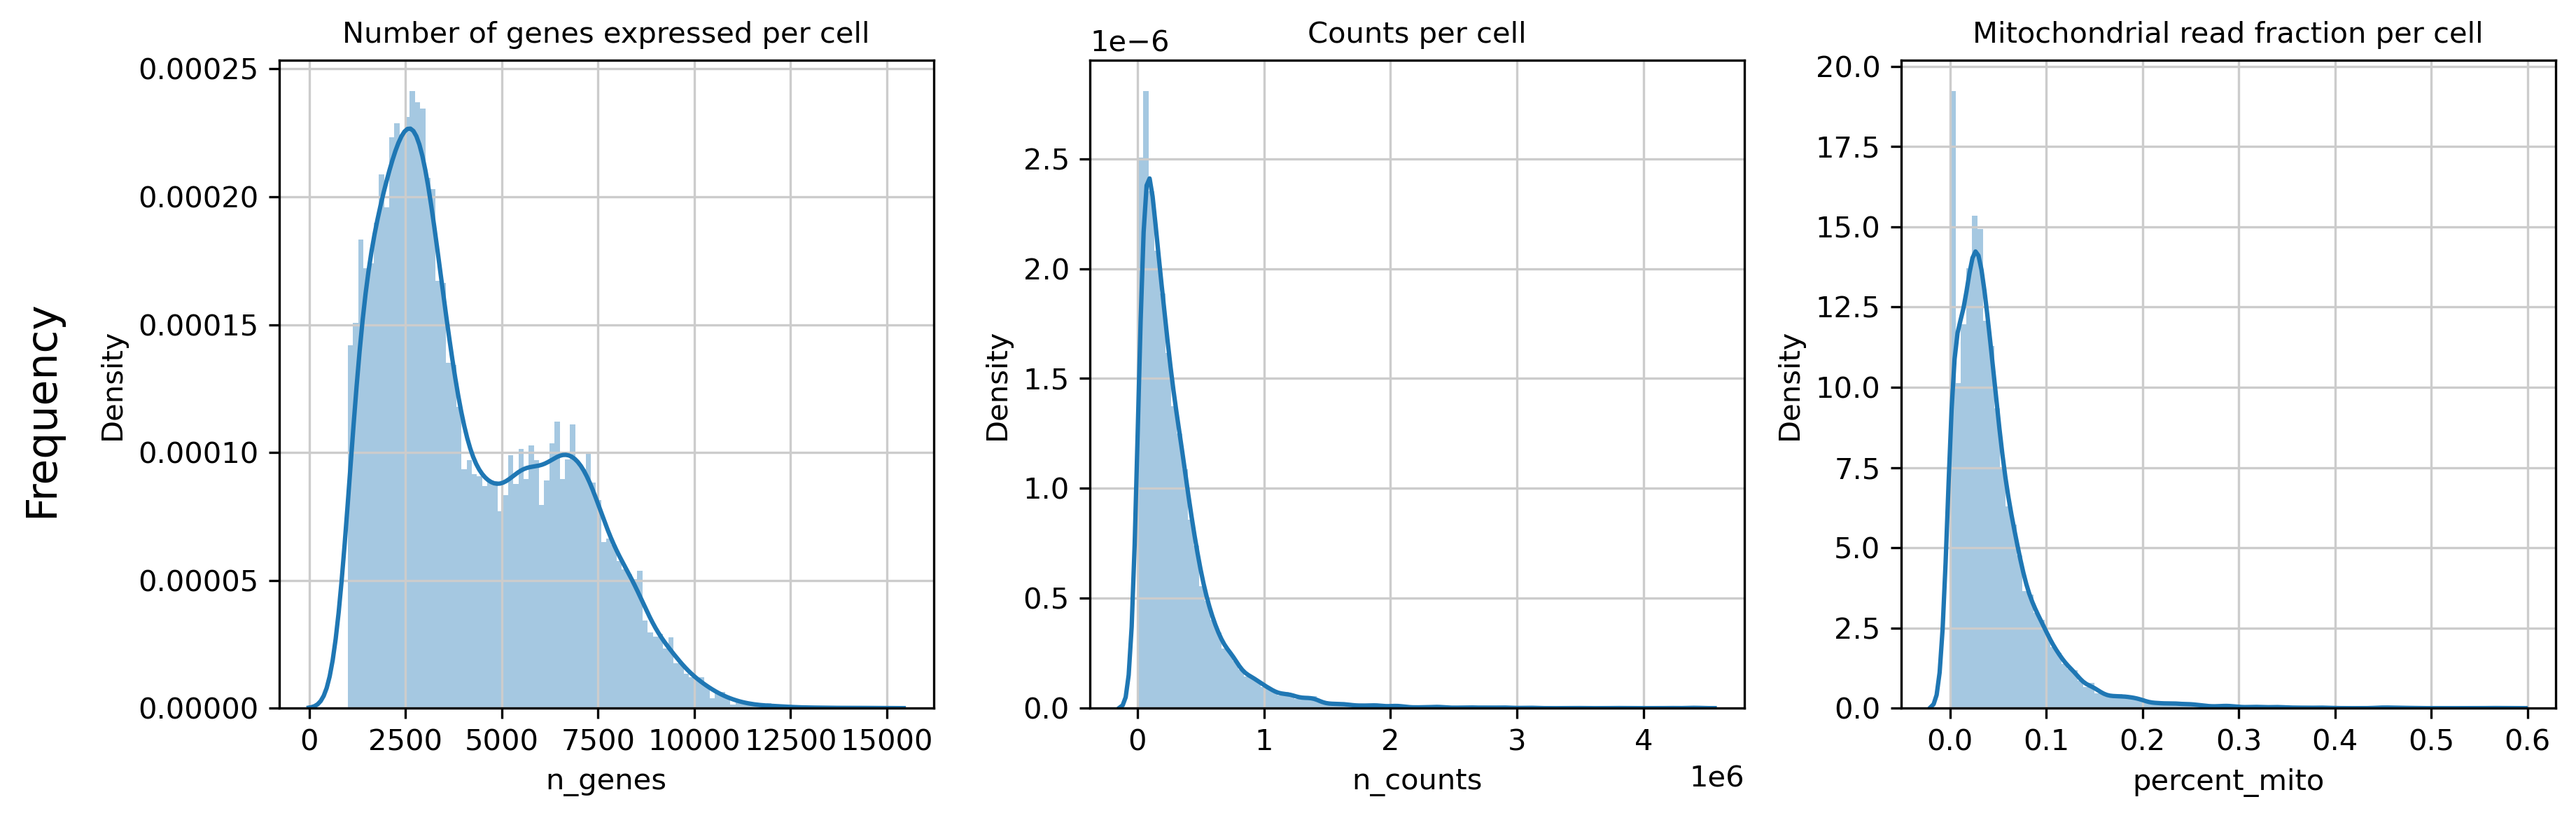

In [21]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

sns.distplot( adata.obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
sns.distplot( adata.obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
sns.distplot( adata.obs['percent_mito'], ax=ax3, norm_hist=True, bins=100)

ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel/filtering_panel_prefilter.pdf', dpi=600, bbox_inches='tight')

### Per sample 

In [22]:
adata.obs

,biosample_id,donor_id,species,species__ontology_label,disease,disease__ontology_label,organ,organ__ontology_label,library_preparation_protocol,library_preparation_protocol__ontology_label,sex,n_genes,percent_mito,n_counts
Cell,,,,,,,,,,,,,,
M21_3p2_Lym_A01_S1,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3184,0.026410,382284.0
M21_3p2_Lym_A02_S2,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,1361,0.011982,36222.0
M21_3p2_Lym_A03_S3,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3412,0.035604,380237.0
M21_3p2_Lym_A04_S4,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3464,0.026559,435867.0
M21_3p2_Lym_A05_S5,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3060,0.000000,366143.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
M29p3_CD3_C12_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,2435,0.045136,285447.0
M29p3_CD3_D01_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3832,0.040228,548148.0
M29p3_CD3_D02_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,2651,0.065831,330652.0


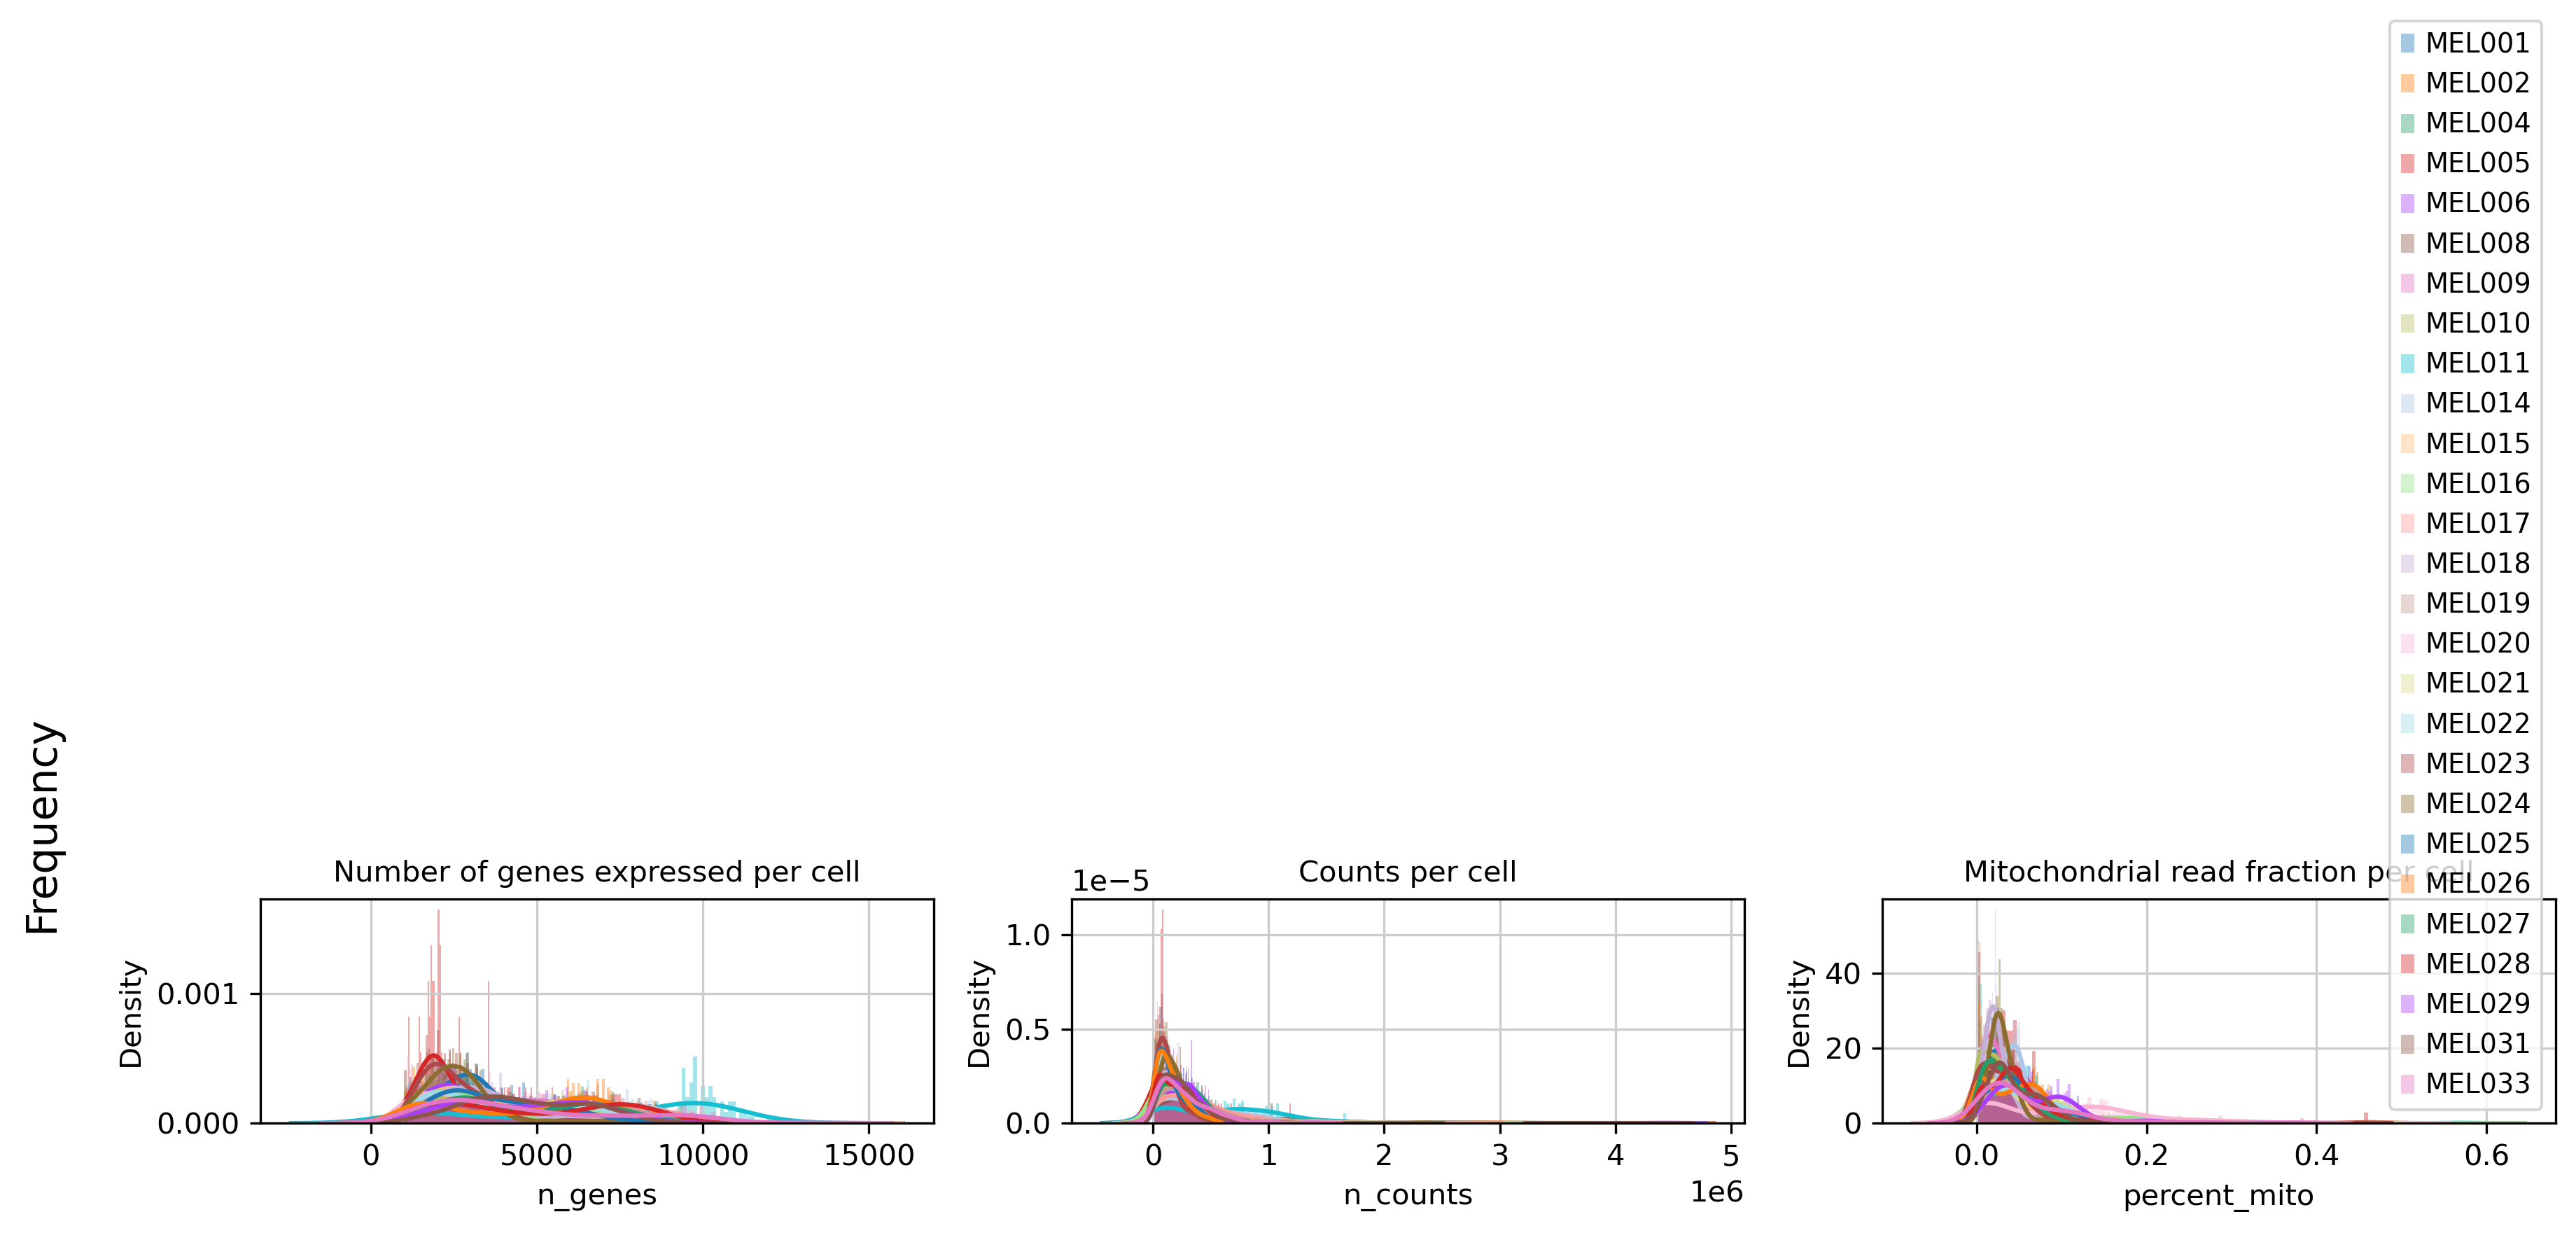

In [23]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

for sample in np.unique(adata.obs.donor_id): # iterate through each sample ID and plot
    
    sns.distplot( adata[adata.obs.donor_id == sample].obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.donor_id == sample].obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.donor_id == sample].obs['percent_mito'], ax=ax3, norm_hist=True, bins=100, label = sample)
    
ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')
ax3.legend()

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel/filtering_panel_prefilter_individual.pdf', dpi=600, bbox_inches='tight')

In [24]:
print(adata.var.index.is_unique)
adata.var_names_make_unique()
print(adata.var.index.is_unique)

True
True


In [25]:
adata.raw = adata
print(adata.raw.var.index.is_unique)

True


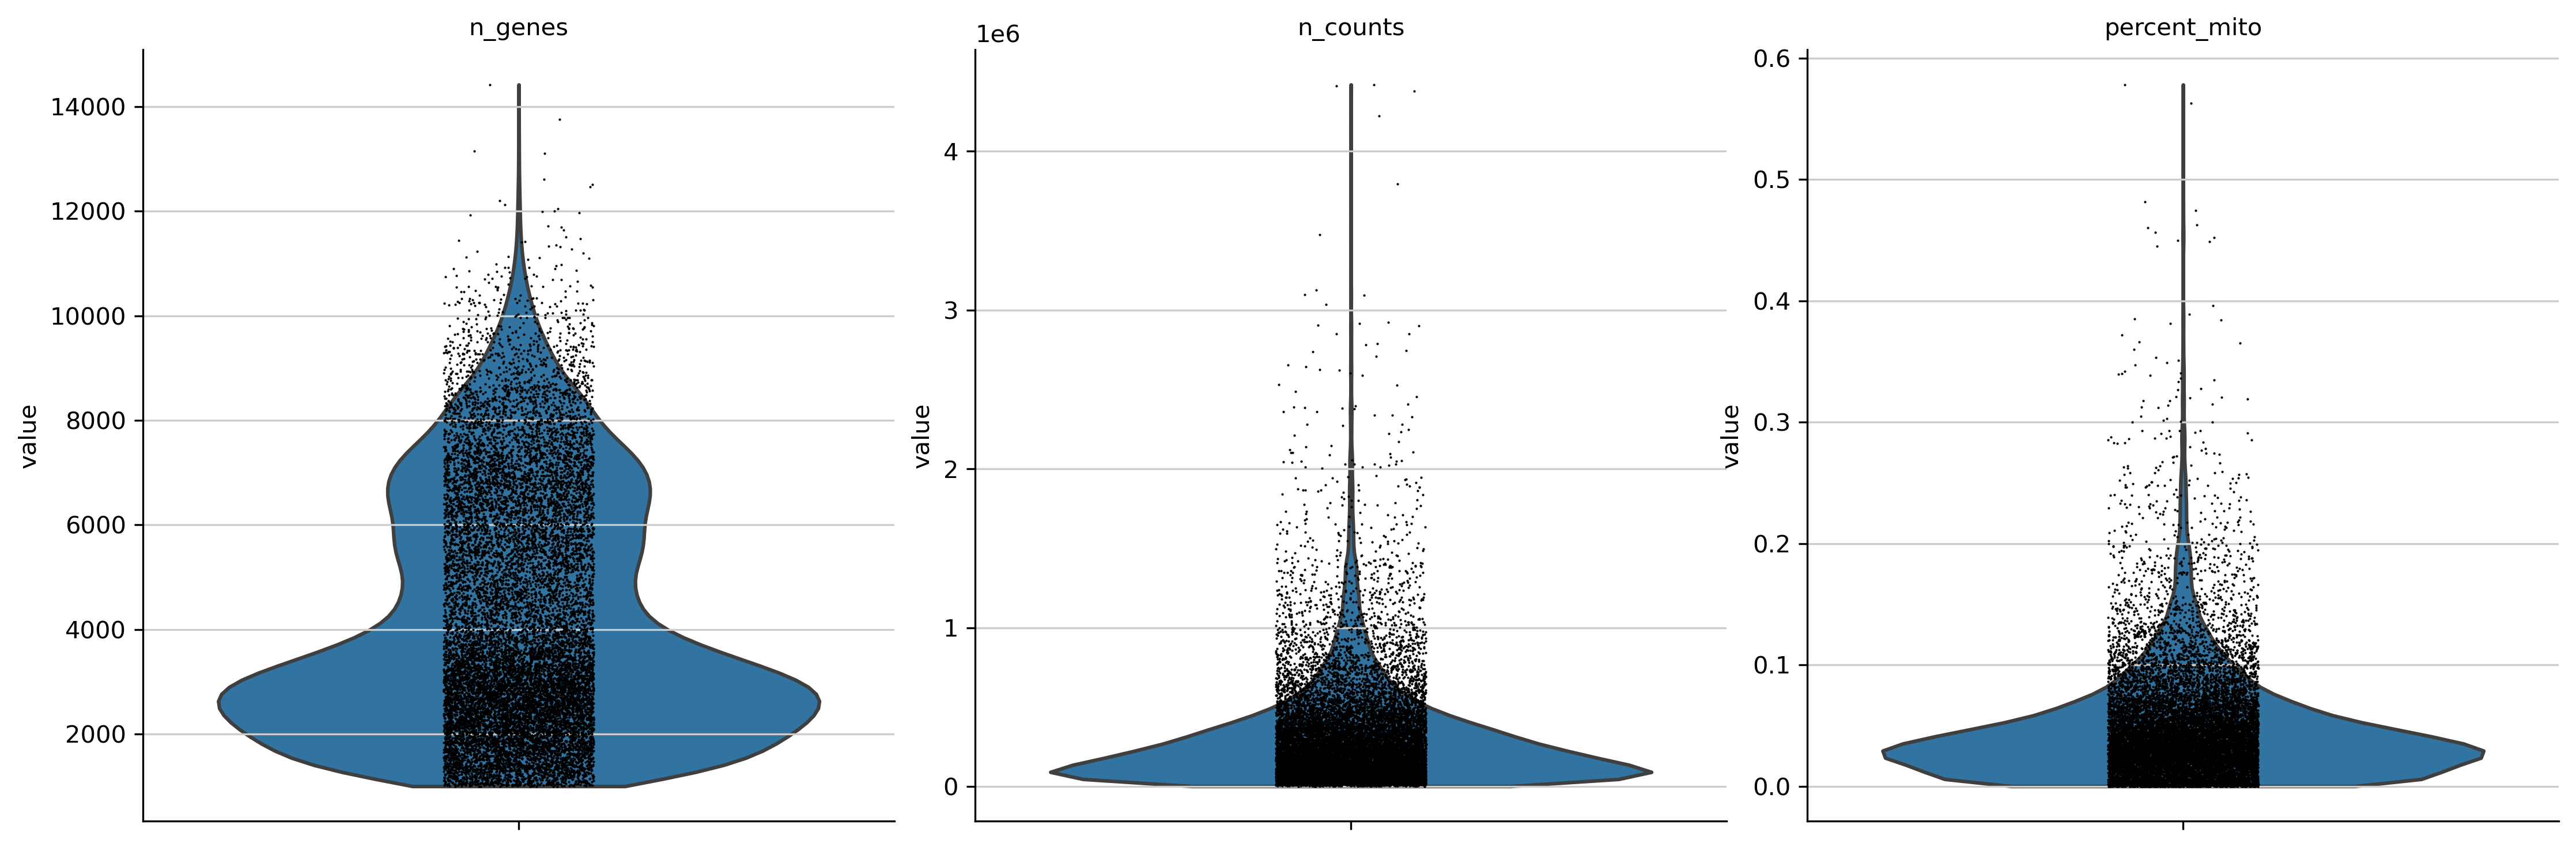

In [26]:
sc.pl.violin(adata, ['n_genes', 'n_counts', 'percent_mito'], multi_panel = True)

### Scatter plot, n_genes by n_counts

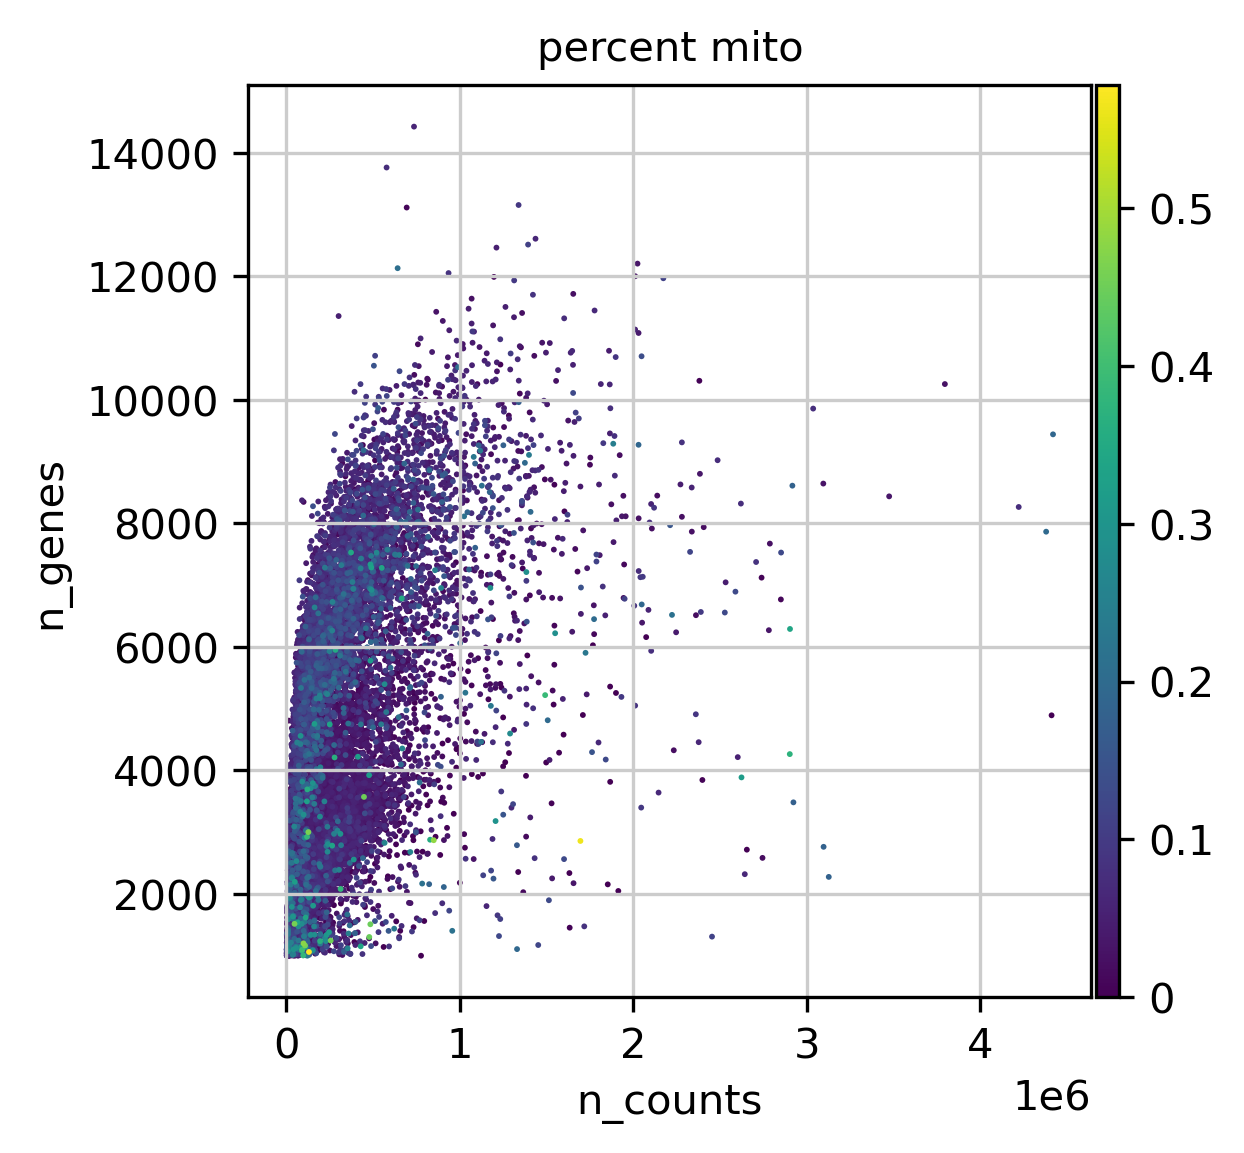

In [27]:
sc.pl.scatter(adata, x='n_counts', y='n_genes', color='percent_mito')

# Carry out filtering steps:

In [28]:
# initial cuts
sc.pp.filter_cells(adata, min_genes=200 )
sc.pp.filter_genes(adata, min_cells=3 )

filtered out 950 genes that are detected in less than 3 cells


In [29]:
adata = adata[adata.obs['n_genes'] < 7000, :]
adata = adata[adata.obs['percent_mito'] < 0.15, :]

# Diagnostic plots, post filtering

### Three-panel summary plots 

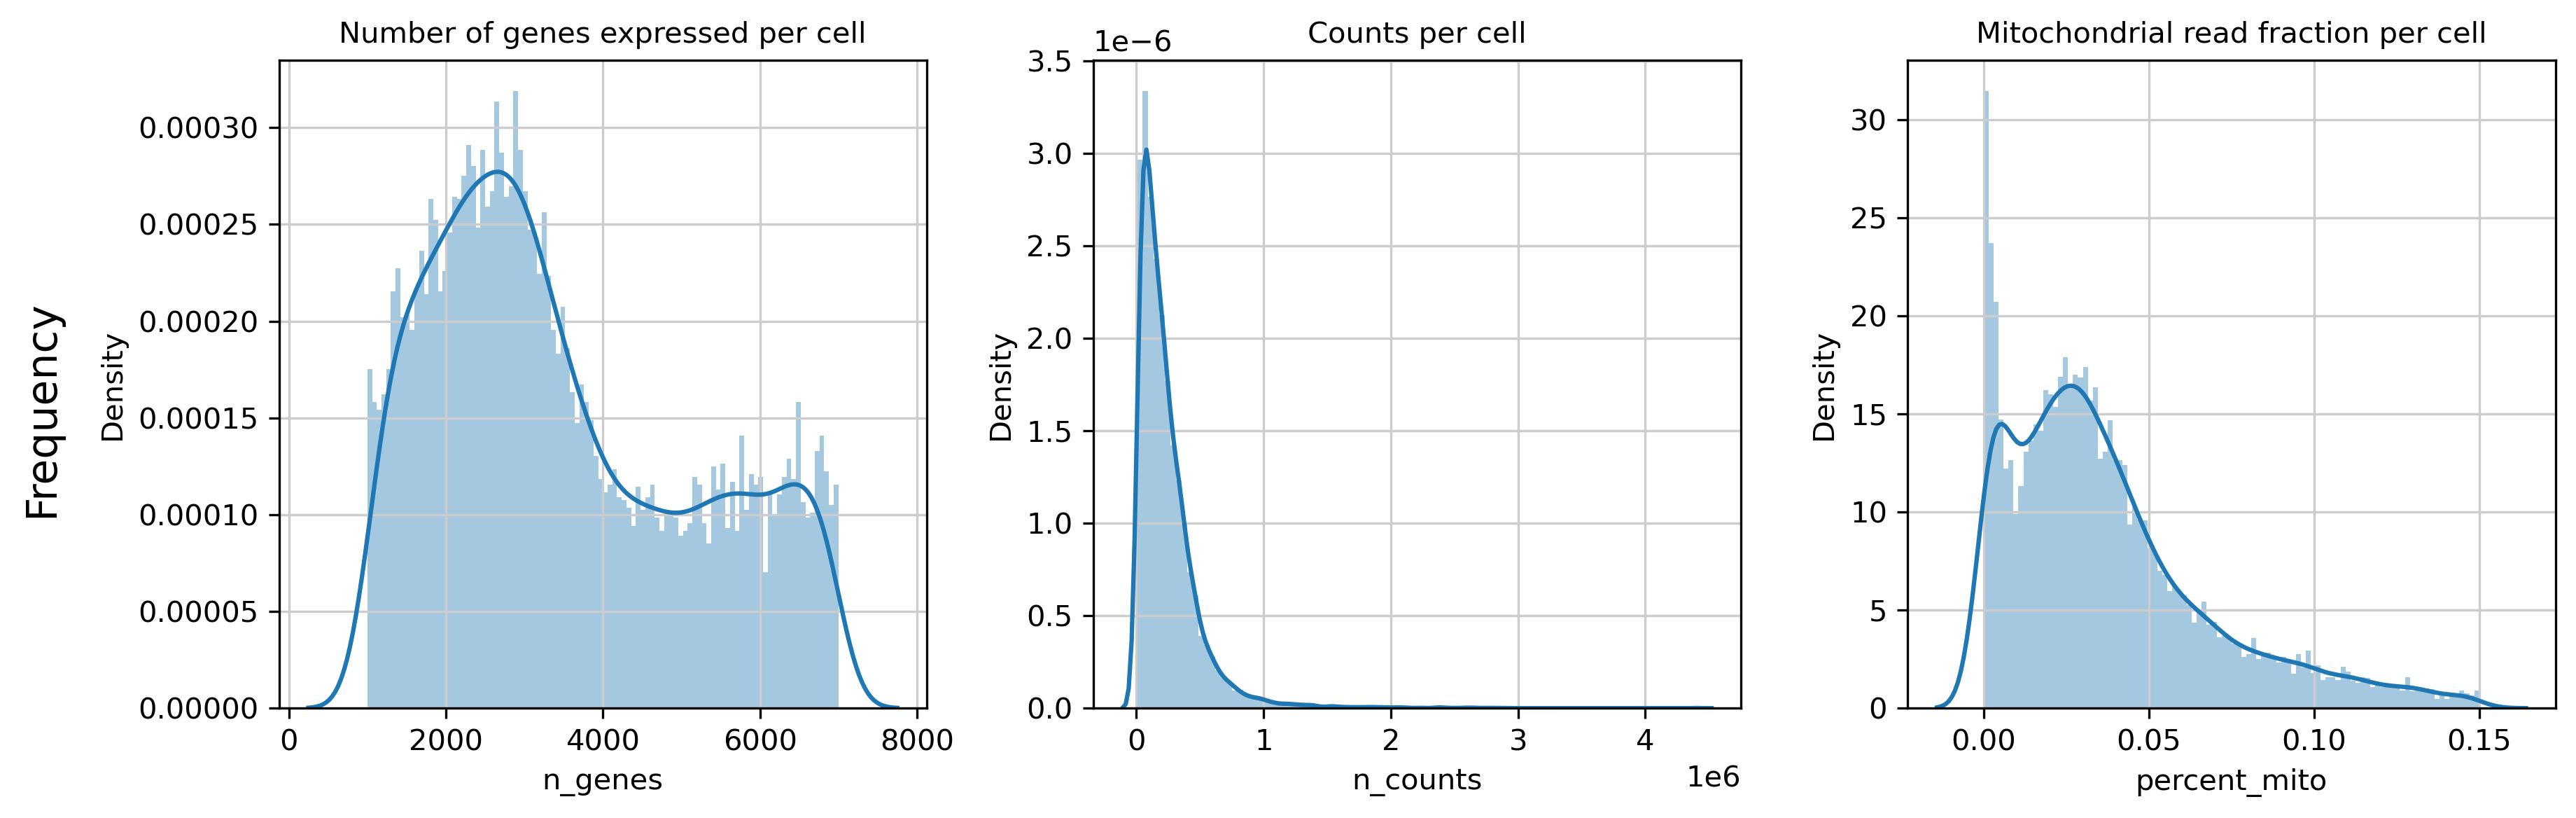

In [30]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

adata.obs['n_genes']

sns.distplot( adata.obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
sns.distplot( adata.obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
sns.distplot( adata.obs['percent_mito'], ax=ax3, norm_hist=True, bins=100)

ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel/filtering_panel_postfilter.pdf', dpi=600, bbox_inches='tight')

### Per sample 

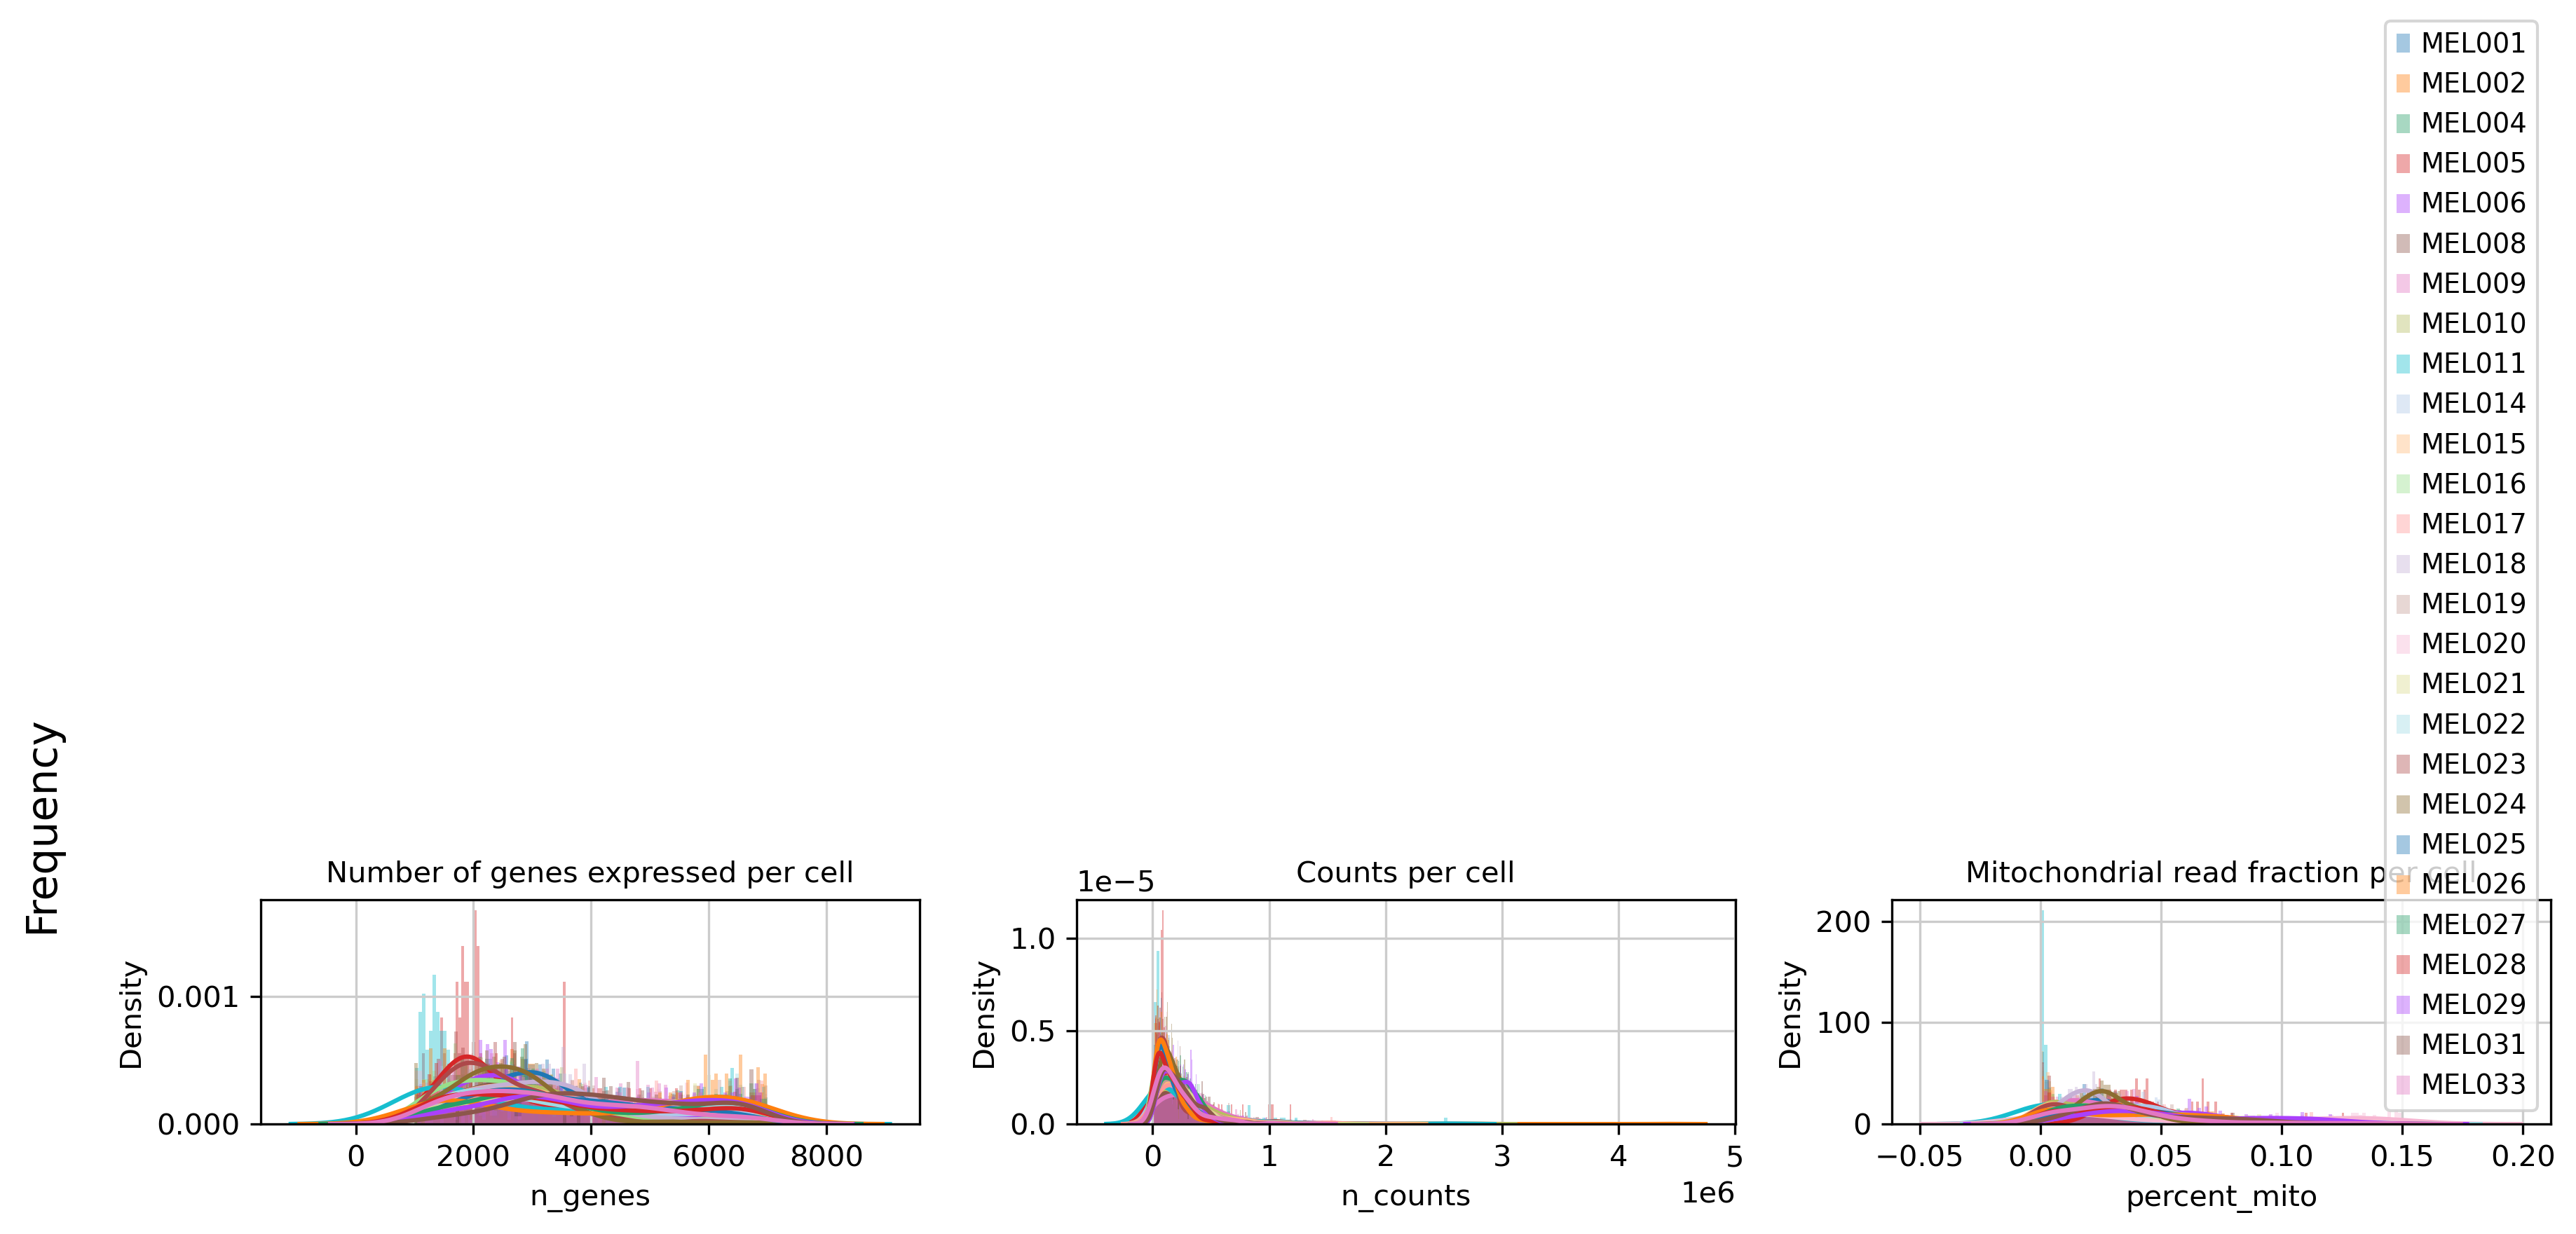

In [31]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

for sample in np.unique(adata.obs.donor_id): # iterate through each sample ID and plot
    
    sns.distplot( adata[adata.obs.donor_id == sample].obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.donor_id == sample].obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.donor_id == sample].obs['percent_mito'], ax=ax3, norm_hist=True, bins=100, label = sample)
    
ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')
ax3.legend()

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel/filtering_panel_postfilter_individual.pdf', dpi=600, bbox_inches='tight')

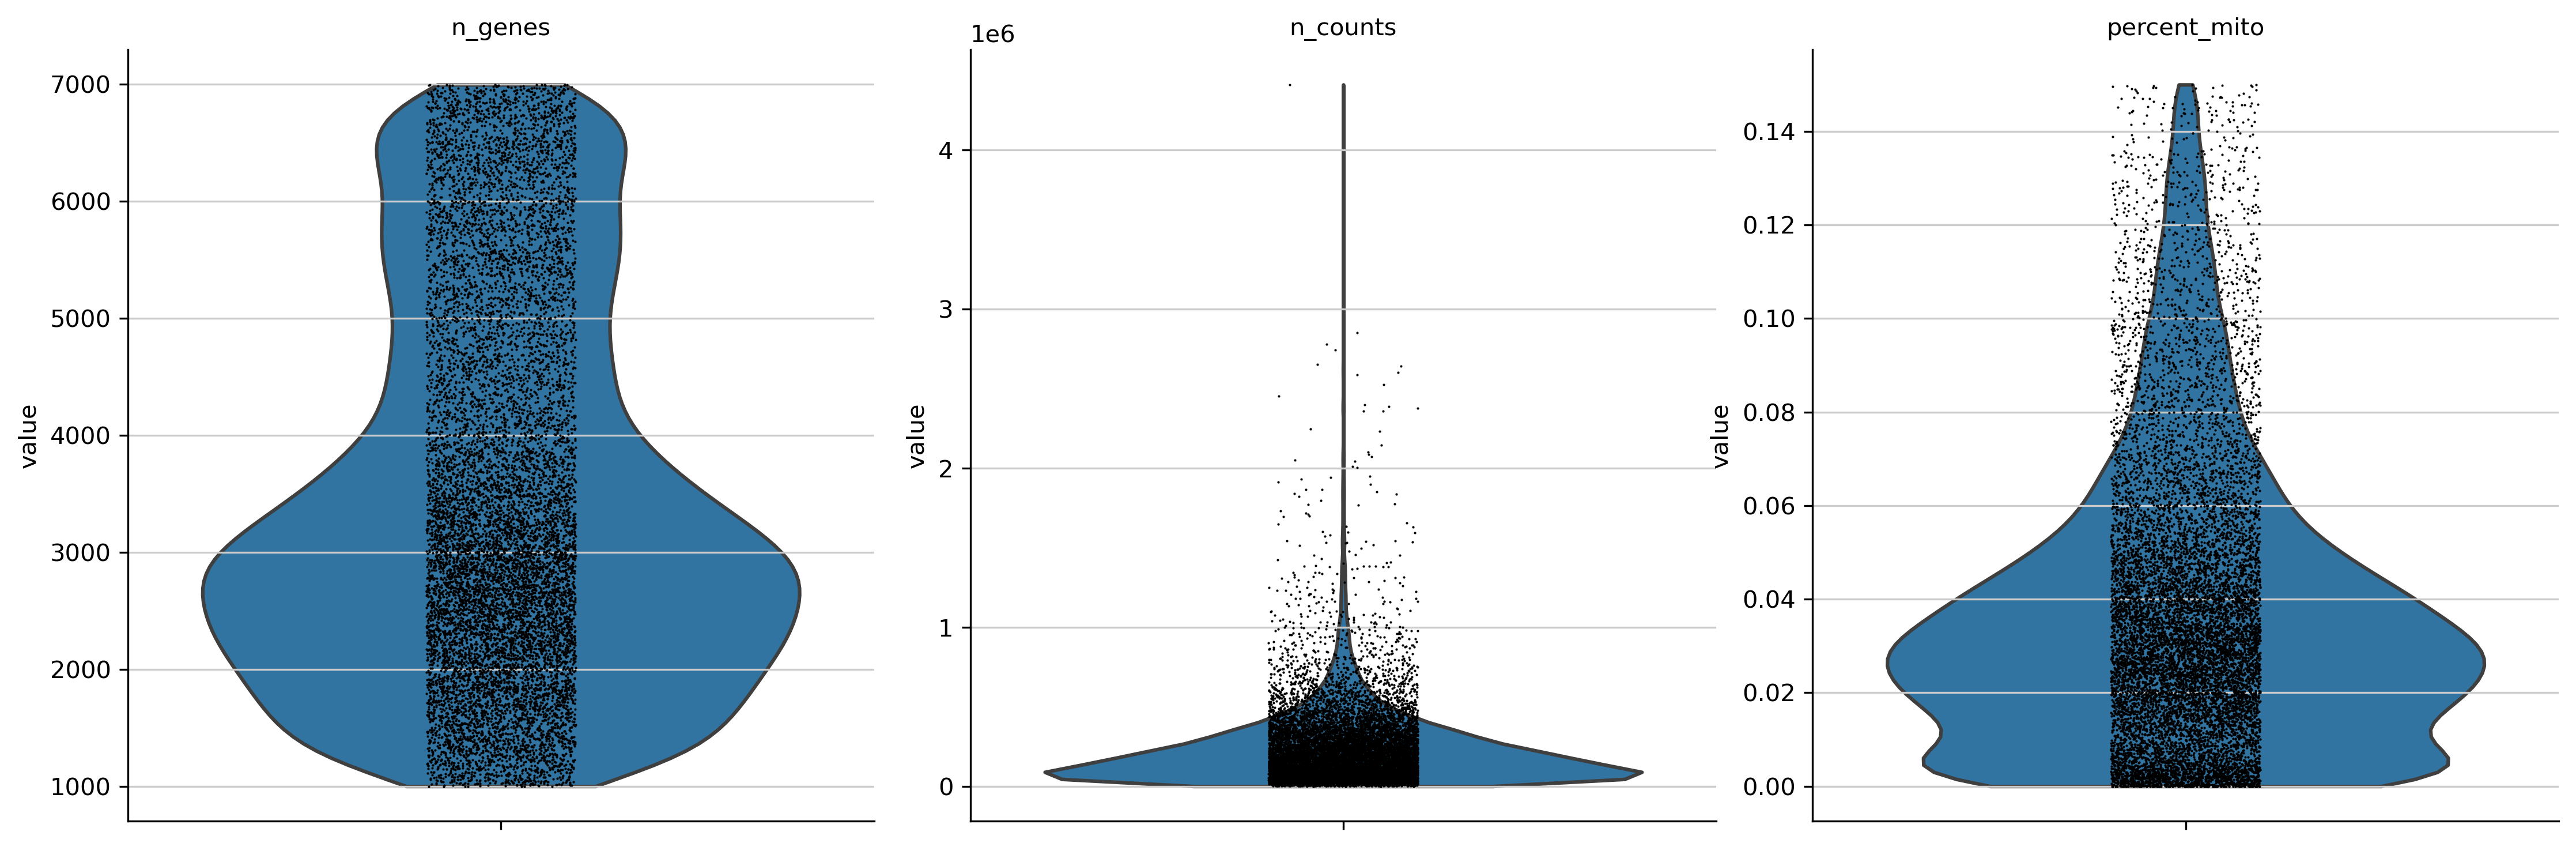

In [32]:
sc.pl.violin(adata, ['n_genes', 'n_counts', 'percent_mito'], multi_panel = True)

### Scatter plot, n_genes by n_counts 

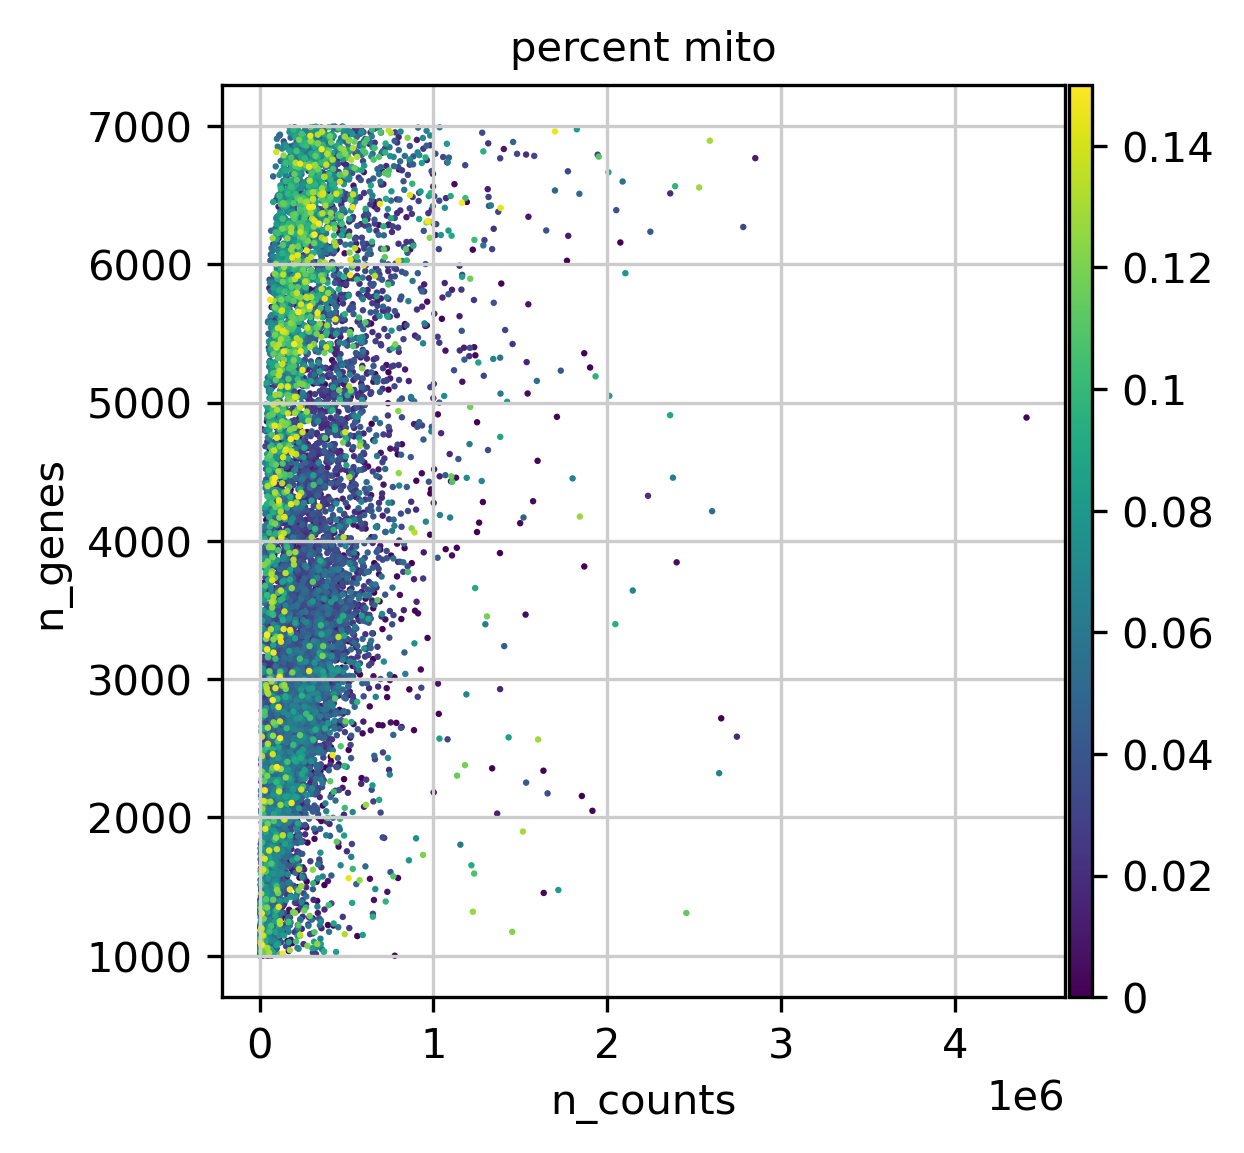

In [33]:
sc.pl.scatter(adata, x='n_counts', y='n_genes', color='percent_mito')

# Finalize the selected filters

Update the anndata file, to be used for further processing, clustering, visualization, etc..



In [34]:
adata.write( f_anndata_path )

# Optionally filter cells by post-qc done by authors

In [35]:
meta_post_umap = pd.read_csv(f_post_umap, delimiter = "\t", skiprows = [1])
meta_post_umap = meta_post_umap.rename(columns={'NAME': 'Cell'})
meta_post_umap = meta_post_umap.set_index("Cell")

In [36]:
meta_post_umap

,cell type,flow,X,Y
Cell,,,,
M21_3p2_Lym_A01_S1,T Cell,CD3+,16.712996,18.405556
M21_3p2_Lym_A02_S2,T Cell,CD3+,16.606333,18.532732
M21_3p2_Lym_A03_S3,T Cell,CD3+,16.736214,17.718025
M21_3p2_Lym_A04_S4,T Cell,CD3+,17.974920,17.677567
M21_3p2_Lym_A05_S5,T Cell,CD3+,17.882086,17.997593
...,...,...,...,...
M29p3_CD3_C12_Lym,T Cell,CD3+,18.541660,16.098431
M29p3_CD3_D01_Lym,T Cell,CD3+,14.685131,17.730236
M29p3_CD3_D02_Lym,T Cell,CD3+,18.426643,15.936874


In [37]:
np.unique(meta_post_umap["flow"])

array(['CD3+', 'CD45+', 'CD45-', 'nucseq'], dtype=object)

In [38]:
meta_post_umap[meta_post_umap["cell type"] == "malignant"]

,cell type,flow,X,Y
Cell,,,,
M33p2_Lym_A08_S296,malignant,CD3+,-6.541142,9.295466
M33p2_Lym_B09_S309,malignant,CD3+,-6.528764,9.282580
M33p2_Lym_C04_S316,malignant,CD3+,-6.533608,9.286810
M33p2_Lym_G03_S363,malignant,CD3+,-6.530167,9.283918
MEL015p9_B08_45neg,malignant,CD45-,-1.302618,7.097083
...,...,...,...,...
M21_2p2_45neg_H06_45pos,malignant,CD45-,-9.714891,21.517401
M21_2p2_45neg_H07_45pos,malignant,CD45-,-9.582990,21.384552
M21_2p2_45neg_H09_45pos,malignant,CD45-,-9.597201,21.398983


In [39]:
adata = adata[adata.obs.index.isin(meta_post_umap.index)]
adata

View of AnnData object with n_obs × n_vars = 11462 × 32220
    obs: 'biosample_id', 'donor_id', 'species', 'species__ontology_label', 'disease', 'disease__ontology_label', 'organ', 'organ__ontology_label', 'library_preparation_protocol', 'library_preparation_protocol__ontology_label', 'sex', 'n_genes', 'percent_mito', 'n_counts'
    var: 'n_cells'

In [40]:
adata.obs["cell_type"] = meta_post_umap["cell type"]

In [41]:
np.unique(adata.obs['cell_type'])

array(['?', 'B Cell', 'IFN-responsive neutrophils',
       'IL-8 high neutrophils', 'T Cell', 'calprotectin-high neutrophils',
       'degranulating\nneutrophil',
       'hypoxia-associated monocyte-derived cluster 1',
       'hypoxia-associated monocyte-derived cluster 2', 'malignant',
       'monocytes/macrophages', 'neural/glial', 'plasma cell',
       'reactive microglia'], dtype=object)

In [42]:
adata.obs

,biosample_id,donor_id,species,species__ontology_label,disease,disease__ontology_label,organ,organ__ontology_label,library_preparation_protocol,library_preparation_protocol__ontology_label,sex,n_genes,percent_mito,n_counts,cell_type
Cell,,,,,,,,,,,,,,,
M21_3p2_Lym_A01_S1,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3184,0.026410,382284.0,T Cell
M21_3p2_Lym_A02_S2,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,1361,0.011982,36222.0,T Cell
M21_3p2_Lym_A03_S3,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3412,0.035604,380237.0,T Cell
M21_3p2_Lym_A04_S4,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3464,0.026559,435867.0,T Cell
M21_3p2_Lym_A05_S5,MEL021_3,MEL021,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3060,0.000000,366143.0,T Cell
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
M29p3_CD3_C12_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,2435,0.045136,285447.0,T Cell
M29p3_CD3_D01_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,3832,0.040228,548148.0,T Cell
M29p3_CD3_D02_Lym,MEL029,MEL029,NCBITaxon_9606,Homo sapiens,MONDO_0005105,melanoma (disease),UBERON_0000955,brain,EFO_0008931,Smart-seq2,unknown,2651,0.065831,330652.0,T Cell


# Dot plot of expression values of genes for each signature in a collection 

In [43]:
# save a copy of the raw data
adata.raw = adata

# Total-count normalize (library-size correct) to 10,000 reads/cell
sc.pp.normalize_per_cell(adata, counts_per_cell_after=1e4)

# log transform the data.
sc.pp.log1p(adata)

# add log transformed data to a layer
adata.layers['log1p'] = adata.X.copy()

# regress out total counts per cell and the percentage of mitochondrial genes expressed
sc.pp.regress_out(adata, ['n_counts', 'percent_mito'] ) #, n_jobs=args.threads)

# scale each gene to unit variance, clip values exceeding SD 10.
sc.pp.scale(adata, max_value=10)

normalizing by total count per cell
    finished (0:00:00): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
regressing out ['n_counts', 'percent_mito']
    sparse input is densified and may lead to high memory use
    finished (0:14:30)


## ERBB3 Expression

# Fig. 4D

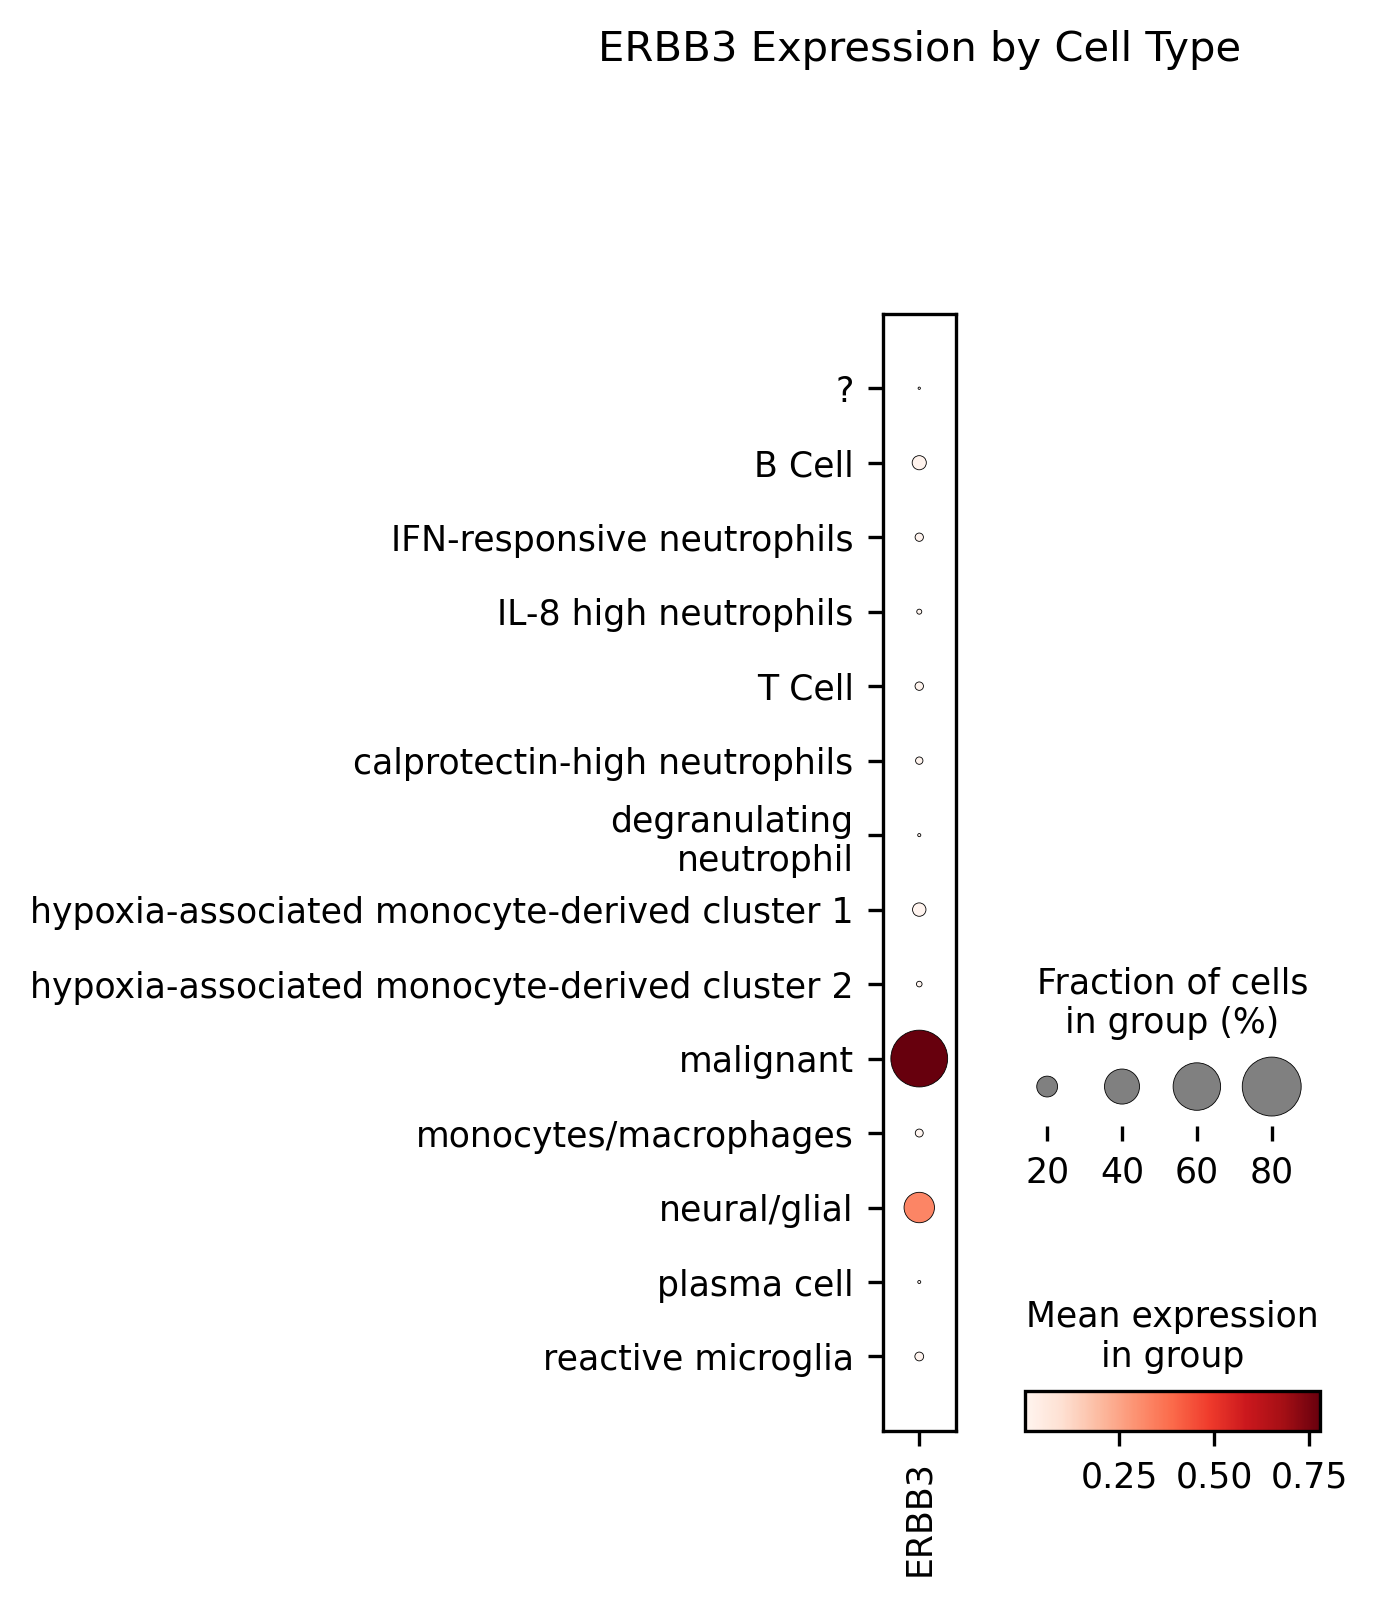

In [56]:
sc.pl.dotplot(adata, 
              var_names = "ERBB3",
              #gene_symbols = "gene_ids",
              groupby = 'cell_type',
              #log = True,
              use_raw = False,
              layer = "log1p",
              #vmin = 2.25,
              #vmax = 2.5,
              dendrogram = False,
              title = f'ERBB3 Expression by Cell Type',)
              #save='Tsoi_louvain.png')